# 20c · On-disk capacity and memory accounting

## The engineering question
What does “on disk” change when the operating system can still cache data in RAM?

**Learning outcomes:** estimate raw vector capacity; measure physical collection allocation; compare in-memory and memory-mapped vectors/HNSW; separate payload/index overhead from vector bytes; avoid false cold-cache claims.

For N float32 vectors of D dimensions, raw storage is 4ND bytes before graph edges, payloads, WAL, and replicas. We build two disposable collections with identical 6,000 × 64 normalized synthetic vectors and 256-character payloads. One uses memory-resident vectors/HNSW; the other sets both structures `on_disk=True`. Server configuration and index readiness are recorded. The host has ample RAM: both variants may be served from OS/VM cache.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("20c", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,on_disk,build_seconds,allocated_collection_bytes,raw_vector_bytes,payload_text_bytes,indexed_vectors
0,False,0.870587,6696960,1536000,1536000,6000
1,True,0.878108,6688768,1536000,1536000,6000


count    median        max
on_disk phase                                  
False   first-pass      50  1.060292  10.627917
        repeat-pass     50  0.929792  10.433834
True    first-pass      50  0.995229  12.856708
        repeat-pass     50  0.912292   1.211792

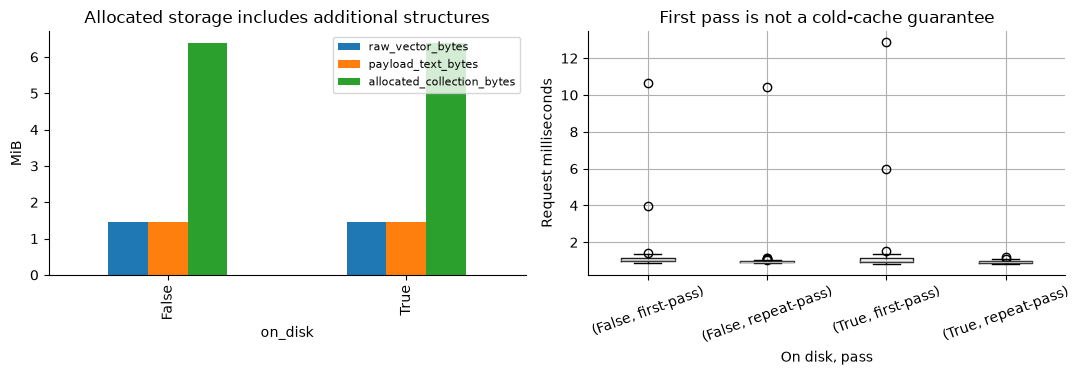

In [2]:
import time
from uuid import uuid4
from qdrant_client import QdrantClient, models as qm
from vector_masterclass.config import qdrant_url
from vector_masterclass.operations import wait_index, collection_storage_bytes

rng = np.random.default_rng(20)
vectors = rng.normal(size=(6000, 64)).astype("float32")
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
probes = rng.normal(size=(50, 64)).astype("float32")
probes /= np.linalg.norm(probes, axis=1, keepdims=True)
client = QdrantClient(url=qdrant_url(), timeout=30)
rows, builds = [], []
for on_disk in [False, True]:
    name = "vmc_20c_" + uuid4().hex[:8]
    client.create_collection(
        name,
        vectors_config=qm.VectorParams(size=64, distance=qm.Distance.COSINE, on_disk=on_disk),
        hnsw_config=qm.HnswConfigDiff(
            m=16, ef_construct=100, full_scan_threshold=10, on_disk=on_disk
        ),
        optimizers_config=qm.OptimizersConfigDiff(indexing_threshold=64, default_segment_number=1),
        on_disk_payload=on_disk,
    )
    try:
        started = time.perf_counter()
        for start in range(0, len(vectors), 256):
            client.upsert(
                name,
                points=[
                    qm.PointStruct(
                        id=i, vector=vectors[i].tolist(), payload={"text": "x" * 256, "ordinal": i}
                    )
                    for i in range(start, min(start + 256, len(vectors)))
                ],
                wait=True,
            )
        info = wait_index(client, name, len(vectors))
        builds.append(
            {
                "on_disk": on_disk,
                "build_seconds": time.perf_counter() - started,
                "allocated_collection_bytes": collection_storage_bytes(name),
                "raw_vector_bytes": vectors.nbytes,
                "payload_text_bytes": len(vectors) * 256,
                "indexed_vectors": info.indexed_vectors_count,
            }
        )
        for phase in ["first-pass", "repeat-pass"]:
            for qi, vector in enumerate(probes):
                started = time.perf_counter()
                hits = client.query_points(
                    name, query=vector.tolist(), limit=10, search_params=qm.SearchParams(hnsw_ef=64)
                ).points
                rows.append(
                    {
                        "on_disk": on_disk,
                        "phase": phase,
                        "query": qi,
                        "milliseconds": 1000 * (time.perf_counter() - started),
                        "returned": len(hits),
                    }
                )
    finally:
        client.delete_collection(name)
client.close()
results = lesson.table(pd.DataFrame(rows))
builds = lesson.table(pd.DataFrame(builds), "capacity")
display(builds)
display(results.groupby(["on_disk", "phase"]).milliseconds.agg(["count", "median", "max"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
builds.set_index("on_disk")[
    ["raw_vector_bytes", "payload_text_bytes", "allocated_collection_bytes"]
].div(2**20).plot.bar(ax=axes[0])
axes[0].set(ylabel="MiB", title="Allocated storage includes additional structures")
axes[0].legend(fontsize=8)
results.boxplot(column="milliseconds", by=["on_disk", "phase"], ax=axes[1], rot=20)
axes[1].set(
    title="First pass is not a cold-cache guarantee",
    ylabel="Request milliseconds",
    xlabel="On disk, pass",
)
fig.suptitle("")
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
“On disk” controls placement/access, not an upper bound on resident cache. Docker memory and process RSS are sampled in the lesson manifest; the container measurement covers all course collections and cannot isolate each row's memory. Disk allocation is measured for each collection directory using `du -sk`; sparse file allocation, preallocation, filesystem behavior, and background optimization affect it. This is not total host disk consumption or peak build space.

**Exercise:** estimate a million 768-dimensional vectors, two replicas, and simultaneous old/new migration indexes. Add payload/index headroom and explain why raw arithmetic alone is insufficient. Design a safe working-set experiment larger than available RAM; do not flush the user's host caches or create that large dataset as part of this small lesson.

Production choices include SSD latency, IOPS, cache locality, index construction headroom, shard size, replication, and recovery time. A warm tiny run cannot predict p99 under memory pressure. [Qdrant storage](https://qdrant.tech/documentation/concepts/storage/).

In [3]:
manifest = lesson.finish(
    {
        "both_placements": set(builds.on_disk) == {False, True},
        "two_hundred_samples": len(results) == 200,
        "all_results_present": bool((results.returned == 10).all()),
        "index_gate_passed": bool((builds.indexed_vectors >= 5940).all()),
        "physical_storage_measured": bool((builds.allocated_collection_bytes > 0).all()),
    },
    observations={
        "cold_cache_claim": False,
        "memory_scope": "whole course container plus notebook, not per-collection isolation",
        "semantic_quality_claim": False,
        "raw_capacity_formula": "N * dimensions * bytes_per_component; then account for payloads, indexes, WAL, copies, replicas and headroom",
    },
)

{
  "artifact": "artifacts/20261031T060924Z-785063/20c",
  "checks": {
    "both_placements": true,
    "two_hundred_samples": true,
    "all_results_present": true,
    "index_gate_passed": true,
    "physical_storage_measured": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.